# 04. Cálculo de acurácia e avaliação do modelo

**Universidade Presbiteriana Mackenzie** · Tecnologia em Banco de Dados · Projeto Aplicado II  
**Grupo Drop Table:** Igor Eduardo Dallan do Couto (RA 10748144), Jaqueline de Oliveira Alves (RA 10755023), Kayo Oliveira Nukui (RA 10356420) e Lucas de Lima Mendes (RA 10756562)  
**Empresa fictícia:** ConectaShop  
**Responsável por este notebook:** Kayo Oliveira Nukui

Este notebook avalia o modelo oficial (TF-IDF com Regressão Logística) nas 6.980 avaliações de teste, que não participaram do treino. Mostramos a matriz de confusão, refazemos à mão as contas de precisão, recall e F1, comparamos o resultado com a Meta 1 (F1 mínimo de 0,80 na classe negativa) e olhamos o comportamento do modelo por outros ângulos: curvas ROC e precisão-recall, validação cruzada, erros típicos e sensibilidade ao limiar.

**Entradas:** `data/processed/teste.csv`, `data/processed/treino.csv` e `data/processed/modelo/modelo_sentimento.joblib`

## 1. Por que não basta olhar a acurácia

A acurácia é a porcentagem de acertos. Em uma base desbalanceada ela engana: como cerca de 62% do teste é positivo, um "modelo" que respondesse sempre "positivo" teria 62% de acurácia sem encontrar nenhuma reclamação.

Como o objetivo principal é encontrar clientes insatisfeitos, olhamos a classe negativa com três medidas:

- **Precisão:** dos comentários que o modelo marcou como negativos, quantos eram negativos? Mede a confiabilidade do alerta.
- **Recall:** dos comentários realmente negativos, quantos o modelo encontrou? Mede a cobertura das queixas.
- **F1:** média harmônica entre precisão e recall. Só é alta quando as duas são altas.

Métricas de regressão (MAE, RMSE, R²) não se aplicam, porque o modelo prevê uma categoria, e não um número. A Regressão Logística tem "regressão" no nome, mas aqui é usada como classificador.

### Bibliotecas utilizadas neste notebook

| Biblioteca | O que faz | Por que usamos neste notebook |
|---|---|---|
| `pandas` | Estrutura de dados em tabela (DataFrame) e leitura de CSV | Ler o conjunto de teste e organizar as métricas |
| `numpy` | Operações numéricas vetorizadas | Operações como a soma da diagonal da matriz de confusão |
| `matplotlib` | Biblioteca de gráficos de baixo nível | Curvas ROC, precisão-recall e demais gráficos |
| `seaborn` | Gráficos estatísticos construídos sobre o matplotlib | Heatmaps da matriz de confusão |
| `joblib` | Serialização de objetos Python, usada pelo scikit-learn para salvar modelos | Carregar o modelo oficial salvo em `modelo_sentimento.joblib` |
| `scikit-learn` (`sklearn.metrics`, `sklearn.model_selection`) | Biblioteca de aprendizado de máquina | Métricas de classificação (acurácia, F1, matriz de confusão, ROC/PR) e validação cruzada |

In [13]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, make_scorer, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Permite rodar o notebook a partir da pasta notebooks/ ou da raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

plt.style.use("seaborn-v0_8-whitegrid")
CLASSES = ["negativo", "neutro", "positivo"]

## 2. Dados de teste e modelo

In [14]:
caminho_teste = BASE_DIR / "data" / "processed" / "teste.csv"
caminho_modelo = BASE_DIR / "data" / "processed" / "modelo" / "modelo_sentimento.joblib"
if not caminho_teste.exists() or not caminho_modelo.exists():
    raise FileNotFoundError("Rode antes os notebooks 02 e 03 (ou python -m src.preparacao e python -m src.treinamento).")

df_teste = pd.read_csv(caminho_teste)
modelo = joblib.load(caminho_modelo)

y_real = df_teste["sentimento"]
y_pred = modelo.predict(df_teste["texto_limpo"])
y_prob = modelo.predict_proba(df_teste["texto_limpo"])
assert list(modelo.classes_) == CLASSES  # as colunas de y_prob seguem esta ordem

distribuicao = pd.DataFrame({
    "avaliacoes": y_real.value_counts(),
    "proporcao_%": (y_real.value_counts(normalize=True) * 100).round(2),
})
print(f"Avaliações de teste: {len(df_teste):,}")
distribuicao

Avaliações de teste: 6,980


,avaliacoes,proporcao_%
sentimento,,
positivo,4298,61.58
negativo,2049,29.36
neutro,633,9.07


## 3. Matriz de confusão

Cada linha é a classe real (vinda da nota) e cada coluna é a classe prevista pelo modelo. A diagonal tem os acertos. A versão normalizada divide cada linha pelo seu total, então a diagonal mostra o recall de cada classe.

,previsto: negativo,previsto: neutro,previsto: positivo,total real
real: negativo,1694,303,52,2049
real: neutro,237,279,117,633
real: positivo,219,440,3639,4298
total previsto,2150,1022,3808,6980


Acertos (diagonal): 5,612 de 6,980


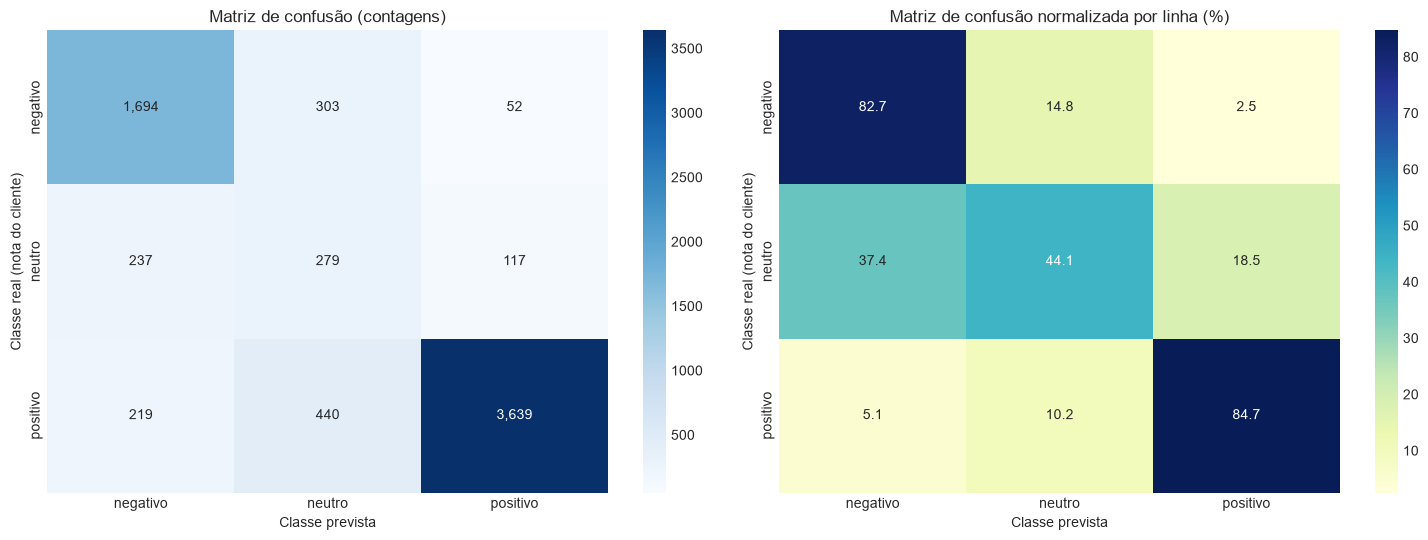

In [15]:
cm = confusion_matrix(y_real, y_pred, labels=CLASSES)

tabela_cm = pd.DataFrame(cm, index=[f"real: {c}" for c in CLASSES], columns=[f"previsto: {c}" for c in CLASSES])
tabela_cm["total real"] = tabela_cm.sum(axis=1)
tabela_cm.loc["total previsto"] = tabela_cm.sum(axis=0)
display(tabela_cm)
print(f"Acertos (diagonal): {np.trace(cm):,} de {cm.sum():,}")

cm_linha = confusion_matrix(y_real, y_pred, labels=CLASSES, normalize="true") * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Matriz de confusão (contagens)")
sns.heatmap(cm_linha, annot=True, fmt=".1f", cmap="YlGnBu", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Matriz de confusão normalizada por linha (%)")
for ax in axes:
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real (nota do cliente)")
plt.tight_layout()
plt.show()

**Leitura.** A maior parte dos erros passa pela classe neutra: muitos positivos e negativos são previstos como neutros, e muitos neutros são previstos como negativos. A matriz mostra onde o modelo erra, mas não a causa. Duas explicações possíveis, a conferir nos exemplos da seção 8: avaliações de nota 3 que trazem elogio e crítica na mesma mensagem, e o peso maior que a classe neutra recebe no treino (`class_weight="balanced"`).

## 4. Contas à mão: um contra todos

Para medir cada classe, olhamos a matriz como se só existissem duas categorias: a classe analisada e "o resto".

- **VP (verdadeiro positivo):** casos da classe que o modelo acertou (diagonal).
- **FP (falso positivo):** casos de outras classes previstos como a classe analisada (total da coluna menos a diagonal).
- **FN (falso negativo):** casos da classe previstos como outra (total da linha menos a diagonal).
- **VN (verdadeiro negativo):** todo o resto, ou seja, total − VP − FP − FN.

Com esses números, precisão = VP / (VP + FP), recall = VP / (VP + FN) e F1 = 2 × VP / (2 × VP + FP + FN). No fim, conferimos as contas com o `classification_report` do scikit-learn.

In [16]:
total = cm.sum()
linhas = []
for i, classe in enumerate(CLASSES):
    vp = cm[i, i]
    fp = cm[:, i].sum() - vp
    fn = cm[i, :].sum() - vp
    vn = total - vp - fp - fn
    precisao = vp / (vp + fp)
    recall = vp / (vp + fn)
    f1 = 2 * vp / (2 * vp + fp + fn)
    linhas.append({"classe": classe, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
                   "precisao": precisao, "recall": recall, "f1": f1, "suporte": vp + fn})

metricas_manuais = pd.DataFrame(linhas).set_index("classe")
display(metricas_manuais.round(4))

relatorio = classification_report(y_real, y_pred, labels=CLASSES, output_dict=True)
for classe in CLASSES:
    assert np.isclose(metricas_manuais.loc[classe, "f1"], relatorio[classe]["f1-score"])
print("As contas manuais batem com o scikit-learn.\n")
print(classification_report(y_real, y_pred, labels=CLASSES, digits=4))

,VP,FP,FN,VN,precisao,recall,f1,suporte
classe,,,,,,,,
negativo,1694,456,355,4475,0.7879,0.8267,0.8069,2049
neutro,279,743,354,5604,0.2730,0.4408,0.3372,633
positivo,3639,169,659,2513,0.9556,0.8467,0.8979,4298


As contas manuais batem com o scikit-learn.

              precision    recall  f1-score   support

    negativo     0.7879    0.8267    0.8069      2049
      neutro     0.2730    0.4408    0.3372       633
    positivo     0.9556    0.8467    0.8979      4298

    accuracy                         0.8040      6980
   macro avg     0.6722    0.7047    0.6806      6980
weighted avg     0.8445    0.8040    0.8203      6980



O relatório também traz duas médias, que não devem ser confundidas com o F1 da classe negativa:

- **macro avg:** média simples das três classes. É puxada para baixo pela classe neutra.
- **weighted avg:** média pesada pelo número de casos de cada classe. Fica perto do resultado da classe positiva, que é a maior.

## 5. Resultado frente à Meta 1

In [17]:
f1_negativo = metricas_manuais.loc["negativo", "f1"]
neg = metricas_manuais.loc["negativo"]
vp_n, fp_n, fn_n = (int(neg[c]) for c in ["VP", "FP", "FN"])
print(f"Acurácia:            {np.trace(cm)} / {total} = {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisão negativa:   {vp_n} / ({vp_n} + {fp_n}) = {neg.precisao:.4f}")
print(f"Recall negativo:     {vp_n} / ({vp_n} + {fn_n}) = {neg.recall:.4f}")
print(f"F1 negativo:         2 x {vp_n} / (2 x {vp_n} + {fp_n} + {fn_n}) = {f1_negativo:.4f}")
print(f"Meta 1 (F1 >= 0,80): {'atingida' if f1_negativo >= 0.80 else 'não atingida'} no teste; diferença de {(f1_negativo - 0.80) * 100:+.2f} ponto percentual")

Acurácia:            5612 / 6980 = 0.8040
Precisão negativa:   1694 / (1694 + 456) = 0.7879
Recall negativo:     1694 / (1694 + 355) = 0.8267
F1 negativo:         2 x 1694 / (2 x 1694 + 456 + 355) = 0.8069
Meta 1 (F1 >= 0,80): atingida no teste; diferença de +0.69 ponto percentual


**Leitura.** O modelo passa do limiar da Meta 1 com folga pequena. A seção 9 mostra que, na validação cruzada, o resultado fica em torno do mesmo valor, e a seção 10 verifica se ele depende de textos repetidos entre treino e teste.

## 6. Curvas ROC

As métricas acima usam uma regra fixa: a classe prevista é a de maior probabilidade. As curvas avaliam outra coisa: se a probabilidade estimada ordena bem os casos, para qualquer limiar de corte. Em cada curva, uma classe é tratada como "positiva" e as outras duas como "resto" (um contra todos).

A área sob a curva ROC (AUC) pode ser lida como a chance de um caso da classe receber probabilidade maior que um caso de fora dela. Vale 0,5 para um palpite aleatório e 1,0 para uma ordenação perfeita.

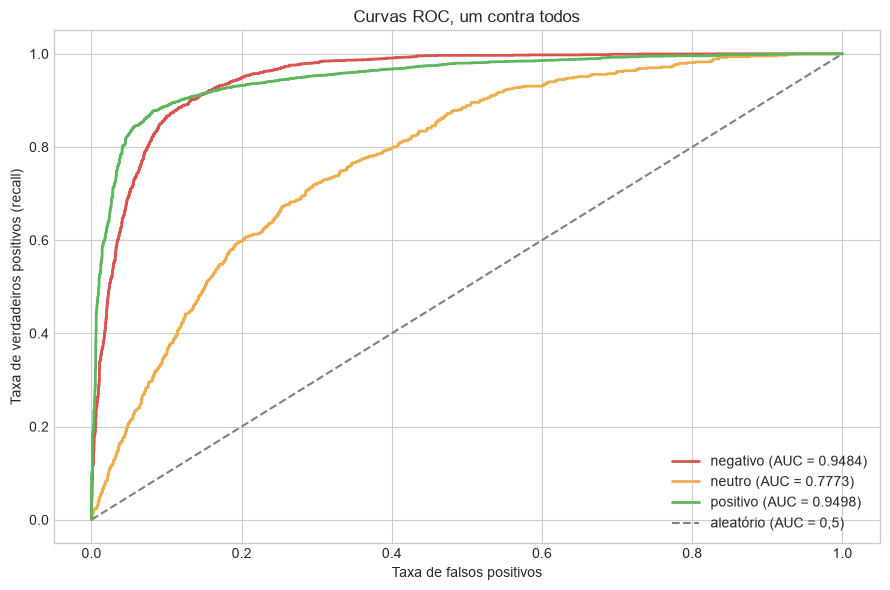

{'negativo': 0.9484, 'neutro': 0.7773, 'positivo': 0.9498}


In [18]:
y_bin = pd.get_dummies(y_real)[CLASSES].to_numpy().astype(int)
cores = {"negativo": "#d9534f", "neutro": "#f0ad4e", "positivo": "#5cb85c"}

roc_auc = {}
plt.figure(figsize=(9, 6))
for i, classe in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc[classe] = roc_auc_score(y_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, color=cores[classe], lw=2, label=f"{classe} (AUC = {roc_auc[classe]:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="aleatório (AUC = 0,5)")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos (recall)")
plt.title("Curvas ROC, um contra todos")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
print({k: round(v, 4) for k, v in roc_auc.items()})

## 7. Curvas precisão-recall

Em classes pequenas, a curva ROC pode parecer otimista, porque a grande quantidade de casos "de fora" dilui os falsos positivos. A curva precisão-recall mostra diretamente quanto a precisão cai quando tentamos encontrar mais casos. O resumo é a precisão média (average precision), e a referência de um modelo sem informação é a proporção da classe no teste.

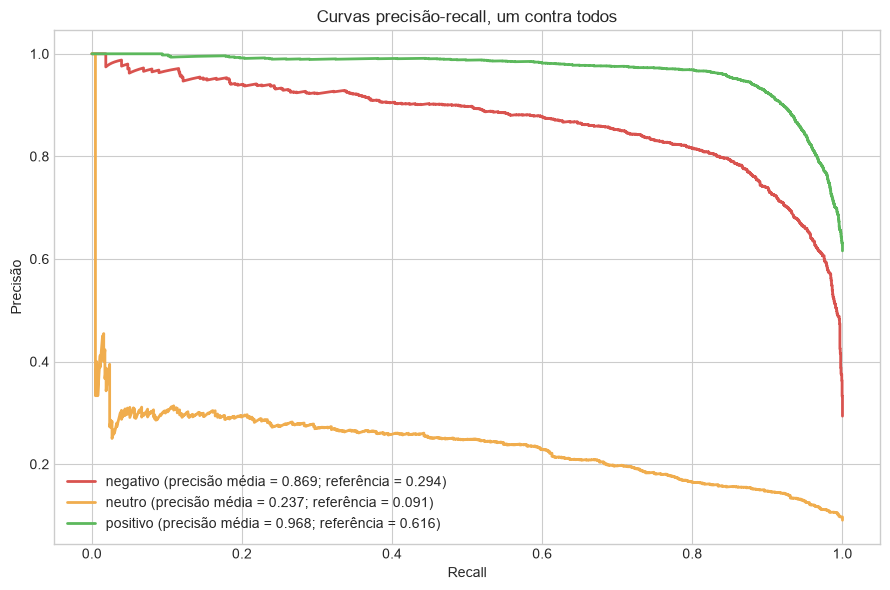

{'negativo': 0.869, 'neutro': 0.2366, 'positivo': 0.968}


In [19]:
precisao_media = {}
plt.figure(figsize=(9, 6))
for i, classe in enumerate(CLASSES):
    p, r, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
    precisao_media[classe] = average_precision_score(y_bin[:, i], y_prob[:, i])
    plt.plot(r, p, color=cores[classe], lw=2,
             label=f"{classe} (precisão média = {precisao_media[classe]:.3f}; referência = {y_bin[:, i].mean():.3f})")
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curvas precisão-recall, um contra todos")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()
print({k: round(v, 4) for k, v in precisao_media.items()})

**Leitura.** Negativo e positivo têm curvas bem acima da referência. A curva do neutro fica perto da referência, o que confirma que o modelo quase não consegue separar essa classe. Nenhuma dessas curvas diz se as probabilidades estão calibradas; elas avaliam só a ordenação.

## 8. Erros típicos

Alguns exemplos ajudam a entender onde o modelo falha. Falsos negativos são clientes insatisfeitos que o modelo não marcou como negativos; falsos positivos são comentários não negativos marcados como negativos.

In [20]:
erros = df_teste.assign(previsto=y_pred)
falsos_negativos = erros[(erros["sentimento"] == "negativo") & (erros["previsto"] != "negativo")]
falsos_positivos = erros[(erros["sentimento"] != "negativo") & (erros["previsto"] == "negativo")]
print(f"Falsos negativos: {len(falsos_negativos):,} de {(erros['sentimento'] == 'negativo').sum():,} negativos reais")
print(f"Falsos positivos: {len(falsos_positivos):,}\n")

def mostrar(tabela, titulo, n=3):
    print(titulo)
    for _, linha in tabela.head(n).iterrows():
        print(f"- nota {linha['review_score']}, previsto {linha['previsto']}: {linha['texto_original'][:100]}")
    print()

mostrar(falsos_negativos, "Falsos negativos:")
mostrar(falsos_positivos, "Falsos positivos:")
mostrar(erros[erros["sentimento"] == "neutro"], "Avaliações neutras (nota 3):")

Falsos negativos: 355 de 2,049 negativos reais
Falsos positivos: 456

Falsos negativos:
- nota 1, previsto neutro: demora entrega mais de 30 dias para entregar um produto pequeno !! É demais !
- nota 2, previsto positivo: Kd o rôdo?
- nota 2, previsto neutro: Produto demorou muito para chegar

Falsos positivos:
- nota 4, previsto negativo: Fiquei satisfeita com a entrega mesmo chegando após o natal. Foi um presente para adulto foi fácil e
- nota 5, previsto negativo: 4 produto sem embalagem
- nota 3, previsto negativo: produto correto e no prazo o cd veio solto dentro da embalagem porque o que prende está quebrado não

Avaliações neutras (nota 3):
- nota 3, previsto neutro: O produto não é igual a foto e a entrega não foi feita conforme combinado, tendo eu que retirar em u
- nota 3, previsto negativo: produto correto e no prazo o cd veio solto dentro da embalagem porque o que prende está quebrado não
- nota 3, previsto neutro: Cobrança de frete indevid Sou cliente prime é mesmo assim m

**Leitura.** Há dois tipos de falso negativo nos exemplos: reclamações claras de atraso que o modelo mandou para "neutro" e textos curtos e ambíguos, como "Kd o rôdo?". Entre os falsos positivos aparecem avaliações com nota alta que relatam um problema ("produto sem embalagem"), em que o texto parece mais negativo do que a nota. Nos exemplos de nota 3, o mesmo texto traz elogio e reclamação, e o rótulo vem da nota, não da leitura do texto; isso limita o quanto um modelo treinado só com o texto pode acertar nessa classe.

## 9. Validação cruzada do F1 negativo

O resultado no teste vem de uma única divisão dos dados. Para ver se ele é estável, repetimos o treino em 5 partições do conjunto de treino (o teste não entra aqui) e medimos o F1 da classe negativa em cada uma. O `cross_val_score` cria uma cópia sem treino do pipeline em cada rodada, então o vocabulário do TF-IDF é refeito a cada vez.

In [21]:
df_treino = pd.read_csv(BASE_DIR / "data" / "processed" / "treino.csv")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_neg_scorer = make_scorer(f1_score, labels=["negativo"], average="macro")

notas_cv = cross_val_score(modelo, df_treino["texto_limpo"], df_treino["sentimento"],
                           cv=cv, scoring=f1_neg_scorer, n_jobs=-1)

for i, nota in enumerate(notas_cv, 1):
    print(f"Partição {i}: F1 negativo = {nota:.4f}")
print(f"Média: {notas_cv.mean():.4f} | desvio padrão: {notas_cv.std():.4f}")
print(f"Partições abaixo de 0,80: {(notas_cv < 0.80).sum()} de {len(notas_cv)}")

Partição 1: F1 negativo = 0.8061
Partição 2: F1 negativo = 0.8076
Partição 3: F1 negativo = 0.8085
Partição 4: F1 negativo = 0.8020
Partição 5: F1 negativo = 0.7922
Média: 0.8033 | desvio padrão: 0.0060
Partições abaixo de 0,80: 1 de 5


**Leitura.** O desvio padrão (calculado com `numpy`, sobre as 5 partições) mostra quanto o resultado varia de uma partição para outra; ele não é um intervalo de confiança. A média fica logo acima de 0,80 e uma partição fica abaixo, então o modelo atende à meta com pouca margem.

## 10. Textos repetidos entre treino e teste

O notebook 02 garante que nenhum texto limpo aparece nos dois conjuntos. Mas o TF-IDF remove acentos e ignora palavras de uma letra, então frases como "ótimo tudo certo" e "otimo tudo certo" chegam iguais ao modelo. Aqui contamos quantas avaliações de teste têm exatamente a mesma representação de alguma avaliação de treino e recalculamos as métricas sem elas.

In [22]:
analisador = modelo.named_steps["tfidf"].build_analyzer()
como_o_modelo_ve = lambda texto: " ".join(analisador(texto))

repr_treino = set(df_treino["texto_limpo"].map(como_o_modelo_ve))
repetido = df_teste["texto_limpo"].map(como_o_modelo_ve).isin(repr_treino).to_numpy()

print(f"review_id em comum entre treino e teste: {len(set(df_treino['review_id']) & set(df_teste['review_id']))}")
print(f"Avaliações de teste com representação igual à de uma avaliação de treino: {repetido.sum()} ({repetido.mean():.2%})")
print(f"Acurácia nesse grupo: {accuracy_score(y_real[repetido], y_pred[repetido]):.4f}\n")

manter = ~repetido
print(f"Sem essas avaliações ({manter.sum():,} casos):")
print(f"  acurácia    = {accuracy_score(y_real[manter], y_pred[manter]):.4f}")
print(f"  F1 negativo = {f1_score(y_real[manter], y_pred[manter], labels=['negativo'], average='macro'):.4f}")
print("\nExemplos:")
print(df_teste.loc[repetido, ["texto_limpo", "sentimento"]].head(6).to_string())

review_id em comum entre treino e teste: 0
Avaliações de teste com representação igual à de uma avaliação de treino: 123 (1.76%)
Acurácia nesse grupo: 0.9350

Sem essas avaliações (6,857 casos):
  acurácia    = 0.8017
  F1 negativo = 0.8061

Exemplos:
                            texto_limpo sentimento
18  comprei numero mas so recebi numero   negativo
39                     otimo tudo certo   positivo
42                     ainda não testei   positivo
58                o produto é muito bom   positivo
66    produto demorou muito para chegar   negativo
80                             parabéns   positivo


**Leitura.** São avaliações diferentes, de clientes diferentes, com frases curtas e comuns. Não é o mesmo registro vazando para o teste, mas esses casos são mais fáceis para o modelo. Como as métricas quase não mudam sem eles, a conclusão sobre a Meta 1 se mantém. Para a Etapa 3, a checagem do pipeline pode passar a comparar os textos já normalizados dessa forma.

## 11. Sensibilidade ao limiar (exploratório)

Hoje a regra é "classe de maior probabilidade". Se a equipe de atendimento preferir encontrar mais reclamações, mesmo com mais alarmes falsos, uma alternativa seria marcar como negativo todo comentário cuja probabilidade de "negativo" passe de um limiar. A tabela e o gráfico mostram esse trade-off.

Cuidado: este cálculo usa o próprio conjunto de teste, então serve só para visualizar o efeito. Para escolher um limiar de verdade, ele teria de ser definido em validação cruzada no treino e confirmado depois. Além disso, a regra "maior probabilidade entre três classes" não equivale a um limiar fixo na probabilidade de "negativo".

,limiar,alertas,falsos_alertas,precisao,recall,f1
0,0.20,2965,1013,0.6583,0.9527,0.7786
1,0.25,2747,839,0.6946,0.9312,0.7957
2,0.30,2556,700,0.7261,0.9058,0.8061
3,0.35,2396,583,0.7567,0.8848,0.8157
4,0.40,2248,485,0.7843,0.8604,0.8206
5,0.45,2085,400,0.8082,0.8224,0.8152
6,0.50,1942,343,0.8234,0.7804,0.8013
7,0.55,1765,278,0.8425,0.7257,0.7798
8,0.60,1625,231,0.8578,0.6803,0.7588
9,0.65,1460,189,0.8705,0.6203,0.7244


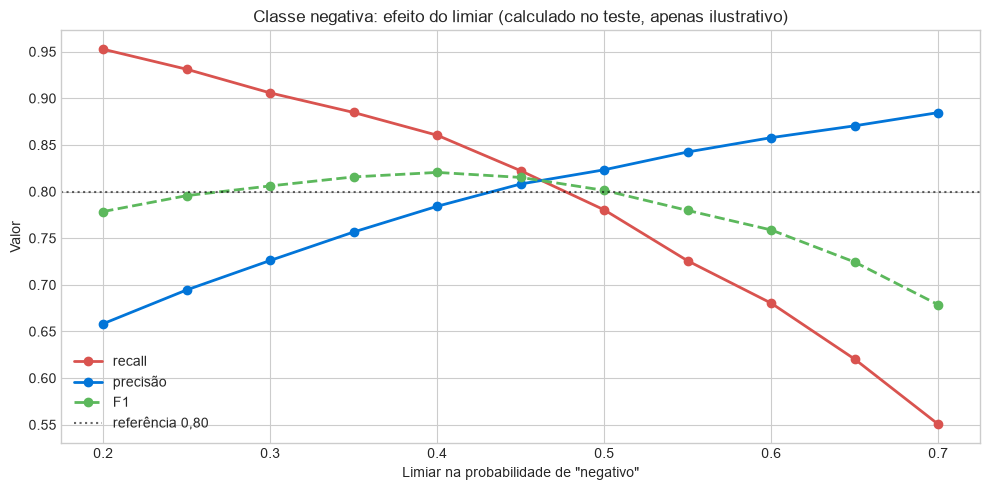

In [23]:
e_negativo = (y_real == "negativo").to_numpy()
prob_negativo = y_prob[:, CLASSES.index("negativo")]

linhas = []
for limiar in np.round(np.arange(0.20, 0.71, 0.05), 2):
    marcado = prob_negativo >= limiar
    vp = (marcado & e_negativo).sum()
    fp = (marcado & ~e_negativo).sum()
    fn = (~marcado & e_negativo).sum()
    linhas.append({"limiar": limiar, "alertas": marcado.sum(), "falsos_alertas": fp,
                   "precisao": vp / (vp + fp), "recall": vp / (vp + fn), "f1": 2 * vp / (2 * vp + fp + fn)})
sensibilidade = pd.DataFrame(linhas)
display(sensibilidade.round(4))

plt.figure(figsize=(10, 5))
plt.plot(sensibilidade["limiar"], sensibilidade["recall"], color="#d9534f", lw=2, marker="o", label="recall")
plt.plot(sensibilidade["limiar"], sensibilidade["precisao"], color="#0275d8", lw=2, marker="o", label="precisão")
plt.plot(sensibilidade["limiar"], sensibilidade["f1"], color="#5cb85c", lw=2, marker="o", linestyle="--", label="F1")
plt.axhline(0.80, color="black", linestyle=":", alpha=0.6, label="referência 0,80")
plt.xlabel("Limiar na probabilidade de \"negativo\"")
plt.ylabel("Valor")
plt.title("Classe negativa: efeito do limiar (calculado no teste, apenas ilustrativo)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 12. Resumo

In [24]:
resumo = pd.DataFrame([
    ["Acurácia (teste)", accuracy_score(y_real, y_pred)],
    ["Precisão negativa (teste)", neg.precisao],
    ["Recall negativo (teste)", neg.recall],
    ["F1 negativo (teste)", f1_negativo],
    ["F1 macro (teste)", relatorio["macro avg"]["f1-score"]],
    ["F1 ponderado (teste)", relatorio["weighted avg"]["f1-score"]],
    ["ROC AUC negativo (teste)", roc_auc["negativo"]],
    ["Precisão média negativo (teste)", precisao_media["negativo"]],
    ["F1 negativo, média da validação cruzada (treino)", notas_cv.mean()],
    ["F1 negativo, desvio padrão da validação cruzada (treino)", notas_cv.std()],
], columns=["medida", "valor"])
resumo.round(4)

,medida,valor
0,Acurácia (teste),0.8040
1,Precisão negativa (teste),0.7879
2,Recall negativo (teste),0.8267
3,F1 negativo (teste),0.8069
4,F1 macro (teste),0.6806
5,F1 ponderado (teste),0.8203
6,ROC AUC negativo (teste),0.9484
7,Precisão média negativo (teste),0.8690
8,"F1 negativo, média da validação cruzada (treino)",0.8033
9,"F1 negativo, desvio padrão da validação cruzad...",0.0060


**Conclusões.**

1. O modelo oficial atinge o F1 mínimo da Meta 1 na classe negativa no teste, com pouca folga. Na validação cruzada a média fica no mesmo patamar (0,803), mas uma das cinco partições fica abaixo de 0,80.
2. A matriz de confusão e as métricas por classe exigidas pela Meta 3 estão documentadas nas seções 3 a 5.
3. A classe neutra é o ponto fraco: baixa precisão, recall moderado e curva precisão-recall perto da referência.
4. As probabilidades ordenam bem os comentários negativos, mas não foram calibradas; qualquer uso de limiar precisa ser validado fora do teste.

*Responsável: Kayo Oliveira Nukui (RA 10356420)*